# Logistic Regression — Baseline (NaN Imputed) — AUC-PR
## IEEE-CIS Fraud Detection | Bitirme Projesi

**Amaç:** LightGBM ve XGBoost modellerine karşı **adil baseline** oluşturmak.

| Özellik | Değer |
|---------|-------|
| Pipeline | LGB/XGB notebook'larıyla özdeş |
| NaN stratejisi | Median imputation (LR NaN desteklemez) |
| Ölçekleme | StandardScaler (X_tr'ye fit, leakage-free) |
| Sınıf dengesi | class_weight='balanced' |
| Birincil metrik | AUC-PR |

## 1. Kütüphaneler

In [ ]:
import os, gc, time, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    confusion_matrix, precision_recall_curve,
)

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 5)
sns.set_style('whitegrid')

_t0_total = time.time()

SAVE_BASE = '/content/drive/My Drive/Bitirme/15-Mayıs-Cuma/'

print('Kutuphaneler yuklendi.')
print(f'SAVE_BASE: {SAVE_BASE}')

Kutuphaneler yuklendi.
SAVE_BASE: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/


## 2. Bellek Optimizasyonu

In [ ]:
def reduce_mem_usage(df: pd.DataFrame, verbose: bool = True) -> pd.DataFrame:
    '''Sayisal sutunlarin veri tipini kuculterek RAM kullanimi azaltir.'''
    start_mem = df.memory_usage(deep=True).sum() / 1024**2
    for col in df.columns:
        col_type = df[col].dtype
        if col_type == object:
            continue
        c_min, c_max = df[col].min(), df[col].max()
        if str(col_type)[:3] == 'int':
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)
        else:
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)
    end_mem = df.memory_usage(deep=True).sum() / 1024**2
    if verbose:
        print(f'Bellek: {start_mem:.1f} MB -> {end_mem:.1f} MB ({100*(start_mem-end_mem)/start_mem:.1f}% azaldi)')
    return df

## 3. Veri Yükleme

In [ ]:
_t_start = time.time()

from google.colab import drive
drive.mount('/content/drive')

DRIVE_DATA_PATH = '/content/drive/My Drive/Bitirme/VeriSeti'
TRAIN_PATH = f'{DRIVE_DATA_PATH}/train_transaction.csv'
IDENT_PATH = f'{DRIVE_DATA_PATH}/train_identity.csv'

os.makedirs(SAVE_BASE, exist_ok=True)

assert os.path.exists(TRAIN_PATH), f'HATA: {TRAIN_PATH}'
assert os.path.exists(IDENT_PATH), f'HATA: {IDENT_PATH}'
print('Dosyalar dogrulandi.')

df_tx = pd.read_csv(TRAIN_PATH)
df_id = pd.read_csv(IDENT_PATH)
df = df_tx.merge(df_id, on='TransactionID', how='left')
del df_tx, df_id
gc.collect()

df = reduce_mem_usage(df)
print(f'Veri seti: {df.shape[0]:,} satir x {df.shape[1]} sutun')
print(f'Fraud orani: {df.isFraud.mean()*100:.2f}% ({df.isFraud.sum():,} fraud / {len(df):,} toplam)')
print(f'[SURE] Veri yukleme: {time.time()-_t_start:.1f} sn')

Mounted at /content/drive
Dosyalar dogrulandi.
Bellek: 2514.0 MB -> 1603.3 MB (36.2% azaldi)
Veri seti: 590,540 satir x 434 sutun
Fraud orani: 3.50% (20,663 fraud / 590,540 toplam)
[SURE] Veri yukleme: 82.8 sn


## 4. Veri Temizleme ve Kategorik Encoding

**NaN stratejisi:** Sayısal NaN'lar bu adımda değiştirilmez.
Median imputation val split'ten sonra uygulanır (leakage önleme).

In [ ]:
_t_start = time.time()

MISSING_THRESHOLD = 0.80
missing_pct = df.isnull().mean()
df_clean = df.loc[:, missing_pct <= MISSING_THRESHOLD].copy()
print(f'{df.shape[1] - df_clean.shape[1]} sutun atildi (>%80 bos)')
print(f'Kalan sutun: {df_clean.shape[1]}')

cat_cols = df_clean.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna('bilinmiyor')

le = LabelEncoder()
for col in cat_cols:
    df_clean[col] = le.fit_transform(df_clean[col].astype(str))

df_clean = reduce_mem_usage(df_clean, verbose=False)
print('Temizlik tamamlandi.')
print(f'[SURE] Temizlik: {time.time()-_t_start:.1f} sn')

74 sutun atildi (>%80 bos)
Kalan sutun: 360
Temizlik tamamlandi.
[SURE] Temizlik: 12.5 sn


## 5. Zaman ve Harcama Özellikleri

In [ ]:
_t_start = time.time()

df_clean['tx_hour']     = (df_clean['TransactionDT'] % 86400) // 3600
df_clean['is_night']    = ((df_clean['tx_hour'] >= 0) & (df_clean['tx_hour'] < 9)).astype(np.int8)
df_clean['tx_day']      = df_clean['TransactionDT'] // 86400
df_clean['day_of_week'] = (df_clean['TransactionDT'] // 86400) % 7
df_clean['log_amt']     = np.log1p(df_clean['TransactionAmt']).astype(np.float32)
df_clean['amt_dollars'] = df_clean['TransactionAmt'].astype(np.int32)
df_clean['amt_cents']   = ((df_clean['TransactionAmt'] % 1) * 100).round().astype(np.int8)

print('Zaman ve harcama ozellikleri eklendi.')
print(f'[SURE] Zaman ozellikleri: {time.time()-_t_start:.1f} sn')

Zaman ve harcama ozellikleri eklendi.
[SURE] Zaman ozellikleri: 0.1 sn


## 6. Temporal Split (%80 Train / %20 Test, Kronolojik)

In [ ]:
_t_start = time.time()

split_idx = int(len(df_clean) * 0.80)
DROP_COLS_EARLY = ['TransactionID', 'isFraud']

X_train = df_clean.iloc[:split_idx].drop(columns=DROP_COLS_EARLY).copy().reset_index(drop=True)
y_train = df_clean.iloc[:split_idx]['isFraud'].reset_index(drop=True)
X_test  = df_clean.iloc[split_idx:].drop(columns=DROP_COLS_EARLY).copy().reset_index(drop=True)
y_test  = df_clean.iloc[split_idx:]['isFraud'].reset_index(drop=True)

print(f'Egitim seti : {X_train.shape[0]:,} islem | Fraud: {y_train.mean()*100:.2f}%')
print(f'Test seti   : {X_test.shape[0]:,} islem  | Fraud: {y_test.mean()*100:.2f}%')
del df_clean, df
gc.collect()
print(f'[SURE] Temporal split: {time.time()-_t_start:.1f} sn')

Egitim seti : 472,432 islem | Fraud: 3.51%
Test seti   : 118,108 islem  | Fraud: 3.44%
[SURE] Temporal split: 2.5 sn


## 7. Kronolojik Sıralama

In [ ]:
_t_start = time.time()

sort_idx_train = X_train['TransactionDT'].argsort(kind='stable')
X_train = X_train.iloc[sort_idx_train].reset_index(drop=True)
y_train = y_train.iloc[sort_idx_train].reset_index(drop=True)

sort_idx_test = X_test['TransactionDT'].argsort(kind='stable')
X_test = X_test.iloc[sort_idx_test].reset_index(drop=True)
y_test = y_test.iloc[sort_idx_test].reset_index(drop=True)

print(f'X_train monoton artan: {X_train["TransactionDT"].is_monotonic_increasing}')
print(f'X_test  monoton artan: {X_test["TransactionDT"].is_monotonic_increasing}')
print(f'[SURE] Siralama: {time.time()-_t_start:.1f} sn')

X_train monoton artan: True
X_test  monoton artan: True
[SURE] Siralama: 0.7 sn


## 8. V Sütunu Grup Seçimi (n_per_group=5)

In [ ]:
_t_start = time.time()

try:
    from tqdm.auto import tqdm as _tqdm
except ImportError:
    import subprocess
    subprocess.run(['pip', 'install', 'tqdm', '-q'], check=True)
    from tqdm.auto import tqdm as _tqdm

def select_v_features(X_train, y_train, n_per_group=5, bucket_size=0.05, min_valid_samples=500):
    v_cols = [c for c in X_train.columns if c.startswith('V')]
    if not v_cols: return []
    missing_rates = X_train[v_cols].isnull().mean()
    buckets = (missing_rates / bucket_size).astype(int)
    selected = []
    for bucket_id in _tqdm(sorted(buckets.unique()), desc='V grup secimi', unit='grup'):
        cols_in_bucket = buckets[buckets == bucket_id].index.tolist()
        corr_dict = {}
        for col in cols_in_bucket:
            valid_mask = X_train[col].notna()
            if valid_mask.sum() < min_valid_samples: continue
            corr_val = abs(X_train.loc[valid_mask, col].corr(y_train[valid_mask]))
            if not np.isnan(corr_val): corr_dict[col] = corr_val
        selected.extend(sorted(corr_dict, key=corr_dict.get, reverse=True)[:n_per_group])
    return selected

all_v_cols = [c for c in X_train.columns if c.startswith('V')]
v_selected = select_v_features(X_train, y_train, n_per_group=5)
v_to_drop  = [c for c in all_v_cols if c not in v_selected]
X_train.drop(columns=v_to_drop, inplace=True)
X_test.drop(columns=v_to_drop, inplace=True)

print(f'V secimi: {len(v_selected)} sutun kaldi, {len(v_to_drop)} atildi.')
print(f'[SURE] V sutun secimi: {time.time()-_t_start:.1f} sn')

V grup secimi:   0%|          | 0/6 [00:00<?, ?grup/s]

V secimi: 30 sutun kaldi, 262 atildi.
[SURE] V sutun secimi: 4.9 sn


## 9. D Sütunu Normalizasyonu (Chris Deotte Yöntemi)

In [ ]:
_t_start = time.time()

D_SKIP = {1, 2, 3, 5, 9}

def engineer_d_features(X_train, X_test):
    for i in range(1, 16):
        if i in D_SKIP: continue
        col = f'D{i}'
        if col not in X_train.columns: continue
        norm_col = f'{col}_norm'
        X_train[norm_col] = (X_train[col] - X_train['TransactionDT']/np.float32(86400)).astype(np.float32)
        X_test[norm_col]  = (X_test[col]  - X_test['TransactionDT'] /np.float32(86400)).astype(np.float32)
    return X_train, X_test

X_train, X_test = engineer_d_features(X_train, X_test)
print('D normalizasyonu tamamlandi.')
print(f'[SURE] D normalizasyon: {time.time()-_t_start:.1f} sn')

D normalizasyonu tamamlandi.
[SURE] D normalizasyon: 0.0 sn


## 10. D1n Hesaplama ve UID Oluşturma

In [ ]:
_t_start = time.time()

if 'D1' in X_train.columns:
    X_train['D1n'] = np.floor(X_train['tx_day'] - X_train['D1']).astype(np.float32)
    X_test['D1n']  = np.floor(X_test['tx_day']  - X_test['D1']).astype(np.float32)
else:
    X_train['D1n'] = np.nan
    X_test['D1n']  = np.nan

uid_train = (X_train['card1'].astype(str) + '_' +
             X_train['addr1'].fillna(-1).astype(int).astype(str) + '_' +
             X_train['D1n'].fillna(-999).astype(int).astype(str))
uid_test  = (X_test['card1'].astype(str) + '_' +
             X_test['addr1'].fillna(-1).astype(int).astype(str) + '_' +
             X_test['D1n'].fillna(-999).astype(int).astype(str))

print(f'Benzersiz UID (train): {uid_train.nunique():,}')
print(f'Benzersiz UID (test) : {uid_test.nunique():,}')
print(f'[SURE] D1n ve UID: {time.time()-_t_start:.1f} sn')

Benzersiz UID (train): 182,535
Benzersiz UID (test) : 57,097
[SURE] D1n ve UID: 0.8 sn


## 11. Velocity Özellikleri (Expanding Window, Leakage-Free)

In [ ]:
_t_start = time.time()

X_train['_uid'] = uid_train.values
X_test['_uid']  = uid_test.values

X_train['uid_tx_count'] = X_train.groupby('_uid').cumcount().astype(np.float32)
for col, out in [('TransactionAmt','uid_amt_mean'),('TransactionAmt','uid_amt_std'),('tx_hour','uid_hour_mean')]:
    if out.endswith('_std'):
        X_train[out] = X_train.groupby('_uid')[col].transform(lambda x: x.expanding().std().shift(1)).astype(np.float32)
    else:
        X_train[out] = X_train.groupby('_uid')[col].transform(lambda x: x.expanding().mean().shift(1)).astype(np.float32)

X_train['_target'] = y_train.values
X_train['uid_fraud_mean'] = X_train.groupby('_uid')['_target'].transform(lambda x: x.expanding().mean().shift(1)).astype(np.float32)
uid_fraud_rate_map = X_train.groupby('_uid')['_target'].mean()
X_train.drop(columns=['_target'], inplace=True)

uid_stats = X_train.groupby('_uid').agg(
    uid_amt_mean_base=('TransactionAmt','mean'), uid_amt_std_base=('TransactionAmt','std'),
    uid_hour_mean_base=('tx_hour','mean'),       uid_tx_count_base=('TransactionAmt','count'))
for col, base in [('uid_tx_count','uid_tx_count_base'),('uid_amt_mean','uid_amt_mean_base'),
                  ('uid_amt_std','uid_amt_std_base'),('uid_hour_mean','uid_hour_mean_base')]:
    X_test[col] = X_test['_uid'].map(uid_stats[base]).astype(np.float32)
X_test['uid_fraud_mean'] = X_test['_uid'].map(uid_fraud_rate_map).astype(np.float32)

X_train.drop(columns=['_uid'], inplace=True)
X_test.drop(columns=['_uid'], inplace=True)
print('Velocity ozellikleri eklendi.')
print(f'[SURE] Velocity: {time.time()-_t_start:.1f} sn')

Velocity ozellikleri eklendi.
[SURE] Velocity: 210.3 sn


## 12. UID Statik Agregasyonlar ve M Sütunu Ortalamaları

In [ ]:
_t_start = time.time()

X_train['_uid'] = uid_train.values
X_test['_uid']  = uid_test.values

uid_agg = X_train.groupby('_uid').agg(
    uid_mean_amt=('TransactionAmt','mean'), uid_std_amt=('TransactionAmt','std'),
    uid_count=('TransactionAmt','count'),   uid_max_amt=('TransactionAmt','max'))
if 'card2' in X_train.columns:
    uid_agg['uid_nunique_card2'] = X_train.groupby('_uid')['card2'].nunique()
for col in uid_agg.columns:
    X_train[col] = X_train['_uid'].map(uid_agg[col]).astype(np.float32)
    X_test[col]  = X_test['_uid'].map(uid_agg[col]).astype(np.float32)

m_cols = [c for c in X_train.columns if c.startswith('M') and c[1:].isdigit()]
for col in m_cols:
    out = f'uid_{col}_mean'
    uid_m = X_train.groupby('_uid')[col].mean()
    X_train[out] = X_train['_uid'].map(uid_m).astype(np.float32)
    X_test[out]  = X_test['_uid'].map(uid_m).astype(np.float32)

X_train.drop(columns=['_uid'], inplace=True)
X_test.drop(columns=['_uid'], inplace=True)
print(f'[SURE] UID agregasyon + M ortalamalari: {time.time()-_t_start:.1f} sn')

[SURE] UID agregasyon + M ortalamalari: 7.7 sn


## 13. Tutar Ratio ve Z-Score Özellikleri

In [ ]:
_t_start = time.time()

for df_ in [X_train, X_test]:
    if 'uid_mean_amt' in df_.columns:
        df_['amt_ratio']  = (df_['TransactionAmt'] / (df_['uid_mean_amt'] + 1e-6)).astype(np.float32)
    if 'uid_mean_amt' in df_.columns and 'uid_std_amt' in df_.columns:
        df_['amt_zscore'] = ((df_['TransactionAmt'] - df_['uid_mean_amt']) /
                             (df_['uid_std_amt'].fillna(1.0) + 1e-6)).astype(np.float32)

print('amt_ratio, amt_zscore eklendi.')
print(f'[SURE] Tutar ratio: {time.time()-_t_start:.1f} sn')

amt_ratio, amt_zscore eklendi.
[SURE] Tutar ratio: 0.0 sn


## 14. UID Target Encoding — Val Split'ten ÖNCE (Leakage-Free)

In [ ]:
_t_start = time.time()

X_train['_uid']    = uid_train.values
X_test['_uid']     = uid_test.values
X_train['_target'] = y_train.values

X_train['uid_target_enc'] = (X_train.groupby('_uid')['_target']
    .transform(lambda x: x.expanding().mean().shift(1)).astype(np.float32))
uid_fraud_rate = X_train.groupby('_uid')['_target'].mean()
X_test['uid_target_enc'] = X_test['_uid'].map(uid_fraud_rate).astype(np.float32)

X_train.drop(columns=['_uid','_target'], inplace=True)
X_test.drop(columns=['_uid'], inplace=True)
print('UID target encoding tamamlandi (leakage-free).')
print(f'[SURE] UID target encoding: {time.time()-_t_start:.1f} sn')

UID target encoding tamamlandi (leakage-free).
[SURE] UID target encoding: 53.8 sn


## 15. Validation Split (Train'in Son %20'si, Kronolojik)

In [ ]:
_t_start = time.time()

val_split_idx = int(len(X_train) * 0.80)
X_tr  = X_train.iloc[:val_split_idx].copy()
y_tr  = y_train.iloc[:val_split_idx].copy()
X_val = X_train.iloc[val_split_idx:].copy()
y_val = y_train.iloc[val_split_idx:].copy()

for df_ in [X_tr, X_val, X_test]:
    if 'TransactionDT' in df_.columns:
        df_.drop(columns=['TransactionDT'], inplace=True)

print(f'X_tr  : {X_tr.shape[0]:,} satir | Fraud: {y_tr.mean()*100:.2f}%')
print(f'X_val : {X_val.shape[0]:,} satir | Fraud: {y_val.mean()*100:.2f}%')
print(f'X_test: {X_test.shape[0]:,} satir | Fraud: {y_test.mean()*100:.2f}%')
print(f'[SURE] Val split: {time.time()-_t_start:.1f} sn')

X_tr  : 377,945 satir | Fraud: 3.41%
X_val : 94,487 satir | Fraud: 3.92%
X_test: 118,108 satir | Fraud: 3.44%
[SURE] Val split: 0.2 sn


## 16. Kategorik Target Encoding — Val Split'ten SONRA (Leakage-Free)

In [ ]:
_t_start = time.time()

cat_te_cols = [c for c in ['card1','card4','card6','ProductCD','P_emaildomain','R_emaildomain']
               if c in X_tr.columns]
global_rate = float(y_tr.mean())

for col in cat_te_cols:
    out = f'{col}_target_enc'
    rate_map = pd.DataFrame({'_cat':X_tr[col].values,'_t':y_tr.values}).groupby('_cat')['_t'].mean()
    for df_ in [X_tr, X_val, X_test]:
        df_[out] = df_[col].map(rate_map).fillna(global_rate).astype(np.float32)

assert X_tr.shape[1] == X_val.shape[1] == X_test.shape[1]
print(f'Kategorik TE tamamlandi: {[f"{c}_target_enc" for c in cat_te_cols]}')
print(f'Final ozellik sayisi: {X_tr.shape[1]}')
print(f'[SURE] Kategorik TE: {time.time()-_t_start:.1f} sn')

Kategorik TE tamamlandi: ['card1_target_enc', 'card4_target_enc', 'card6_target_enc', 'ProductCD_target_enc', 'P_emaildomain_target_enc', 'R_emaildomain_target_enc']
Final ozellik sayisi: 135
[SURE] Kategorik TE: 0.1 sn


## 17. NaN Imputation — Median (LR'ye Özgü)

**Leakage önleme:** `SimpleImputer` yalnızca `X_tr`'ye `fit` edilir.
`X_val` ve `X_test`'e sadece `transform` uygulanır.

LightGBM/XGBoost'un aksine Logistic Regression NaN değerleri desteklemez.

In [ ]:
_t_start = time.time()

imputer = SimpleImputer(strategy='median')
feature_names = X_tr.columns.tolist()

X_tr_imp   = imputer.fit_transform(X_tr)
X_val_imp  = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test)

nan_before = X_tr.isnull().sum().sum()
print(f'Imputation oncesi X_tr NaN sayisi: {nan_before:,}')
print(f'Imputation sonrasi X_tr NaN sayisi: {np.isnan(X_tr_imp).sum():,}')
print(f'[SURE] Imputation: {time.time()-_t_start:.1f} sn')

Imputation oncesi X_tr NaN sayisi: 8,958,711
Imputation sonrasi X_tr NaN sayisi: 0
[SURE] Imputation: 11.4 sn


## 18. Feature Scaling — StandardScaler (LR'ye Özgü)

**Leakage önleme:** `StandardScaler` yalnızca `X_tr`'ye `fit` edilir.

In [ ]:
_t_start = time.time()

scaler = StandardScaler()
X_tr_sc   = scaler.fit_transform(X_tr_imp)
X_val_sc  = scaler.transform(X_val_imp)
X_test_sc = scaler.transform(X_test_imp)

print(f'Scaling tamamlandi.')
print(f'X_tr_sc  : {X_tr_sc.shape}')
print(f'X_val_sc : {X_val_sc.shape}')
print(f'X_test_sc: {X_test_sc.shape}')
print(f'[SURE] Scaling: {time.time()-_t_start:.1f} sn')

Scaling tamamlandi.
X_tr_sc  : (377945, 135)
X_val_sc : (94487, 135)
X_test_sc: (118108, 135)
[SURE] Scaling: 0.8 sn


## 19. Logistic Regression Eğitimi

| Parametre | Değer | Açıklama |
|-----------|-------|----------|
| C | 0.1 | L2 regularization (çok özellik için) |
| class_weight | balanced | Sınıf dengesizliğini telafi eder |
| solver | saga | Büyük veri setleri için uygun |
| max_iter | 1000 | Yakınsama için yeterli |
| random_state | 42 | Tekrar üretilebilirlik |

In [ ]:
_t_start = time.time()

lr_model = LogisticRegression(
    C=0.1,
    penalty='l2',
    class_weight='balanced',
    solver='saga',
    max_iter=1000,
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

lr_model.fit(X_tr_sc, y_tr)

print(f'\nEgitim tamamlandi.')
print(f'Iterasyon sayisi: {lr_model.n_iter_[0]}')
print(f'[SURE] LR egitim: {time.time()-_t_start:.1f} sn')

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.


max_iter reached after 1300 seconds

Egitim tamamlandi.
Iterasyon sayisi: 1000
[SURE] LR egitim: 1300.2 sn


## 20. Tahminler ve Metrikler

In [ ]:
_t_start = time.time()

val_proba  = lr_model.predict_proba(X_val_sc)[:, 1]
test_proba = lr_model.predict_proba(X_test_sc)[:, 1]

val_auc_pr  = average_precision_score(y_val,  val_proba)
test_auc_pr = average_precision_score(y_test, test_proba)
test_roc    = roc_auc_score(y_test, test_proba)

print('=' * 55)
print('  LOGISTIC REGRESSION — METRIKLER')
print('=' * 55)
print(f'  Val  AUC-PR  : {val_auc_pr:.4f}')
print(f'  Test AUC-PR  : {test_auc_pr:.4f}')
print(f'  Test AUC-ROC : {test_roc:.4f}')
print(f'  Val-Test Gap : {val_auc_pr - test_auc_pr:.4f}')
print('=' * 55)
print(f'[SURE] Tahminler: {time.time()-_t_start:.1f} sn')

  LOGISTIC REGRESSION — METRIKLER
  Val  AUC-PR  : 0.6963
  Test AUC-PR  : 0.2607
  Test AUC-ROC : 0.8637
  Val-Test Gap : 0.4356
[SURE] Tahminler: 0.3 sn


## 21. Eşik Analizi

In [ ]:
_t_start = time.time()
RECALL_TARGET = 0.85

def f_beta(prec, rec, beta=1.0):
    denom = (beta**2 * prec + rec)
    return (1 + beta**2) * prec * rec / (denom + 1e-10) if denom > 0 else 0.0

sweep_thresholds = sorted({
    0.001,0.002,0.005,0.01,0.02,0.03,0.04,0.05,
    0.07,0.10,0.15,0.20,0.25,0.30,0.35,0.40,
    0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95
})

rows = []
for t in sweep_thresholds:
    y_pred = (test_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    prec = tp/(tp+fp+1e-10); rec = tp/(tp+fn+1e-10)
    rows.append({'Esik':t,'Recall':rec,'Precision':prec,
                 'F1':f_beta(prec,rec,1.0),'F2':f_beta(prec,rec,2.0),
                 'TP':tp,'FP':fp,'FN':fn,'TN':tn})

df_thr = pd.DataFrame(rows)

H = f"{'Esik':>6} {'Recall':>7} {'Prec':>7} {'F1':>6} {'F2':>6} {'TP':>5} {'FP':>6} {'FN':>5}"
SEP = '-' * len(H)
print('TEST SETI — ESIK TABLOSU (Logistic Regression)')
print(SEP); print(H); print(SEP)
for _, r in df_thr.iterrows():
    flags = []
    if abs(r['Recall']-0.85) < 0.015: flags.append('R~85')
    f2_max = df_thr['F2'].max()
    if abs(r['F2']-f2_max) < 0.001: flags.append('F2-OPT')
    flag_str = ' <-- ' + '+'.join(flags) if flags else ''
    print(f"{r['Esik']:>6.3f} {r['Recall']:>7.4f} {r['Precision']:>7.4f} "
          f"{r['F1']:>6.4f} {r['F2']:>6.4f} "
          f"{int(r['TP']):>5,} {int(r['FP']):>6,} {int(r['FN']):>5,}{flag_str}")
print(SEP)

def find_best_at_recall(target):
    mask = df_thr['Recall'] >= target
    return df_thr[mask].sort_values('Precision', ascending=False).iloc[0] if mask.any() else None
def find_f2_opt():
    return df_thr.sort_values('F2', ascending=False).iloc[0]

op85 = find_best_at_recall(RECALL_TARGET)
op80 = find_best_at_recall(0.80)
f2op = find_f2_opt()
max_rec_row = df_thr.sort_values('Recall', ascending=False).iloc[0]

print()
print('KRITIK NOKTALAR:')
for label, r in [('Recall>=0.85', op85), ('Recall>=0.80', op80), ('F2 Optimal', f2op)]:
    if r is None: print(f'  {label:<22} — ULASILAMADI')
    else: print(f'  {label:<22} esik={r["Esik"]:.3f} recall={r["Recall"]:.4f} prec={r["Precision"]:.4f} F2={r["F2"]:.4f}')
print(f'  {"Maks Recall":<22} esik={max_rec_row["Esik"]:.3f} recall={max_rec_row["Recall"]:.4f} prec={max_rec_row["Precision"]:.4f}')
print(f'[SURE] Esik analizi: {time.time()-_t_start:.1f} sn')

TEST SETI — ESIK TABLOSU (Logistic Regression)
-------------------------------------------------------
  Esik  Recall    Prec     F1     F2    TP     FP    FN
-------------------------------------------------------
 0.001  0.9966  0.0348 0.0672 0.1525 4,050 112,472    14
 0.002  0.9966  0.0348 0.0673 0.1528 4,050 112,194    14
 0.005  0.9958  0.0352 0.0681 0.1544 4,047 110,767    17
 0.010  0.9951  0.0365 0.0705 0.1592 4,044 106,695    20
 0.020  0.9862  0.0393 0.0757 0.1697 4,008 97,850    56
 0.030  0.9845  0.0427 0.0818 0.1819 4,001 89,745    63
 0.040  0.9774  0.0459 0.0877 0.1933 3,972 82,519    92
 0.050  0.9702  0.0492 0.0937 0.2045 3,943 76,193   121
 0.070  0.9464  0.0549 0.1038 0.2228 3,846 66,208   218
 0.100  0.9178  0.0637 0.1191 0.2492 3,730 54,861   334
 0.150  0.8728  0.0787 0.1444 0.2893 3,547 41,502   517
 0.200  0.8351  0.0950 0.1705 0.3264 3,394 32,347   670 <-- R~85
 0.250  0.8044  0.1111 0.1952 0.3578 3,269 26,162   795
 0.300  0.7675  0.1247 0.2146 0.3779 3,119 2

## 22. Precision-Recall Eğrisi

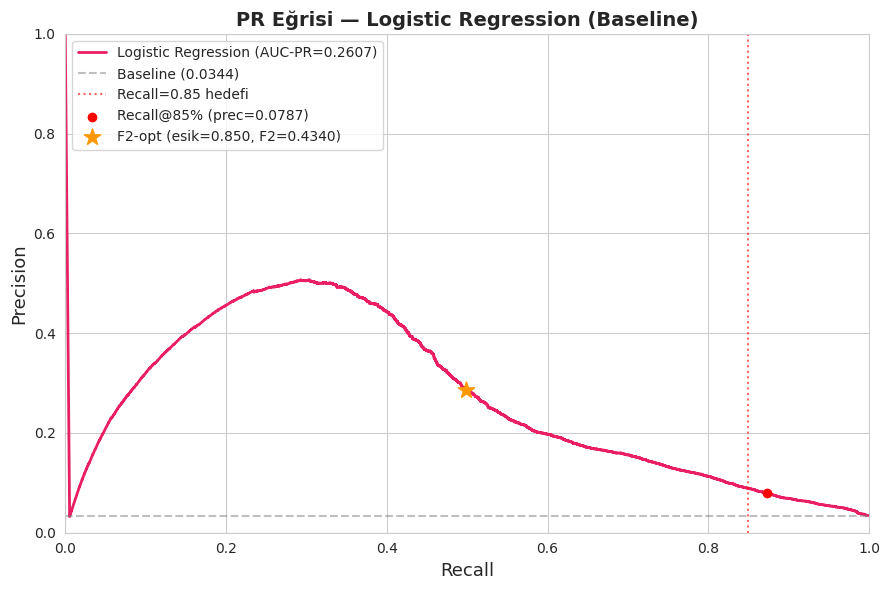

[SURE] PR egrisi: 1.7 sn


In [ ]:
_t_start = time.time()

precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_proba)
baseline_pr = y_test.mean()

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(recall_curve, precision_curve, lw=2, color='#E91E63',
        label=f'Logistic Regression (AUC-PR={test_auc_pr:.4f})')
ax.axhline(y=baseline_pr, color='gray', ls='--', alpha=0.5, label=f'Baseline ({baseline_pr:.4f})')
ax.axvline(x=0.85, color='red', ls=':', alpha=0.6, label='Recall=0.85 hedefi')
if op85 is not None:
    ax.scatter([op85['Recall']], [op85['Precision']], color='red', zorder=5,
               label=f'Recall@85% (prec={op85["Precision"]:.4f})')
ax.scatter([f2op['Recall']], [f2op['Precision']], color='#FF9800', marker='*', s=150, zorder=5,
           label=f'F2-opt (esik={f2op["Esik"]:.3f}, F2={f2op["F2"]:.4f})')
ax.set_xlabel('Recall', fontsize=13)
ax.set_ylabel('Precision', fontsize=13)
ax.set_title('PR Eğrisi — Logistic Regression (Baseline)', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.set_xlim([0, 1]); ax.set_ylim([0, 1])
plt.tight_layout()
plt.savefig(SAVE_BASE + 'lr_baseline_pr_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'[SURE] PR egrisi: {time.time()-_t_start:.1f} sn')

## 23. En Önemli Katsayılar (Top 20 Pozitif / Negatif)

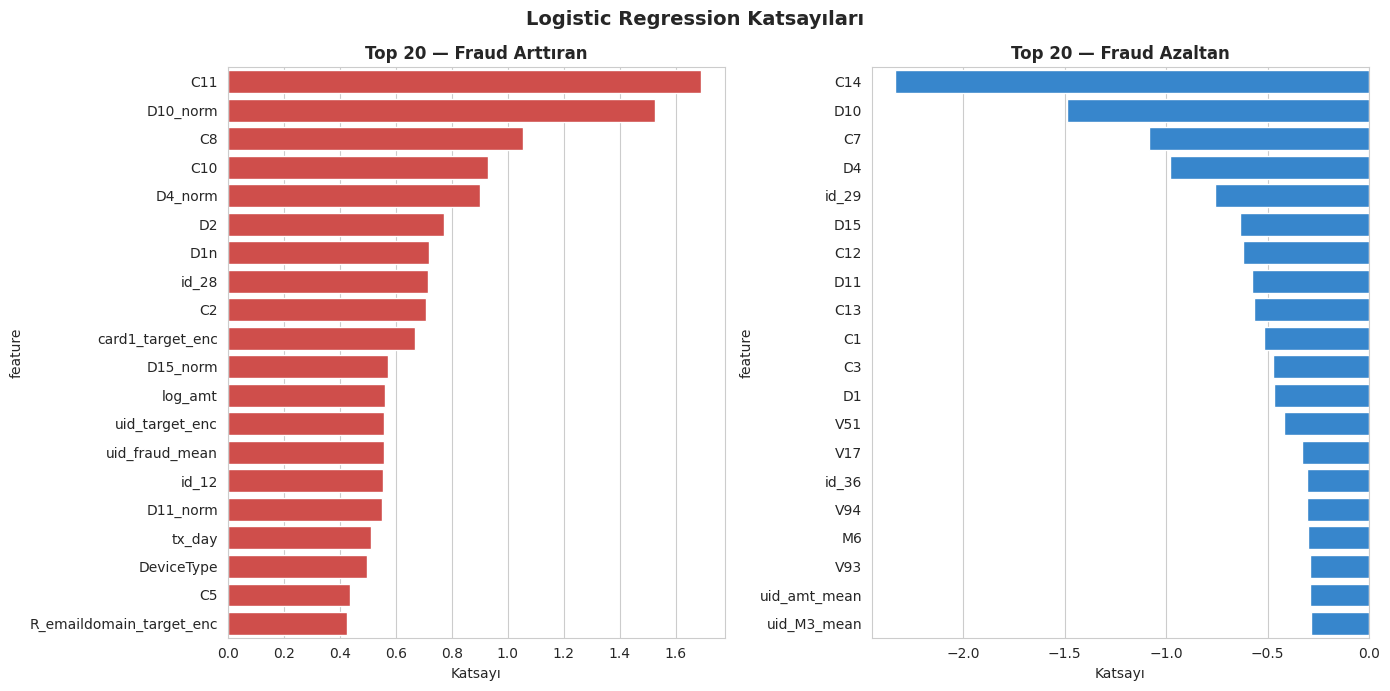

lr_baseline_coefficients.csv kaydedildi.
[SURE] Katsayi analizi: 1.7 sn


In [ ]:
_t_start = time.time()

coef_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': lr_model.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

top_pos = coef_df[coef_df['coefficient'] > 0].head(20)
top_neg = coef_df[coef_df['coefficient'] < 0].head(20)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
sns.barplot(data=top_pos, x='coefficient', y='feature', ax=ax1, color='#E53935')
ax1.set_title('Top 20 — Fraud Arttıran', fontweight='bold')
ax1.set_xlabel('Katsayı')

sns.barplot(data=top_neg, x='coefficient', y='feature', ax=ax2, color='#1E88E5')
ax2.set_title('Top 20 — Fraud Azaltan', fontweight='bold')
ax2.set_xlabel('Katsayı')

plt.suptitle('Logistic Regression Katsayıları', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(SAVE_BASE + 'lr_baseline_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

coef_df.to_csv(SAVE_BASE + 'lr_baseline_coefficients.csv', index=False)
print('lr_baseline_coefficients.csv kaydedildi.')
print(f'[SURE] Katsayi analizi: {time.time()-_t_start:.1f} sn')

## 24. Model ve Sonuçları Kaydet

In [ ]:
_t_start = time.time()
import joblib, datetime

os.makedirs(SAVE_BASE, exist_ok=True)

joblib.dump(lr_model, SAVE_BASE + 'lr_baseline_model.pkl')
print('  lr_baseline_model.pkl kaydedildi.')

df_thr.to_csv(SAVE_BASE + 'lr_baseline_threshold_table.csv', index=False)
print('  lr_baseline_threshold_table.csv kaydedildi.')

record = {
    'tarih'               : datetime.datetime.now().strftime('%Y-%m-%d %H:%M'),
    'model'               : 'Logistic Regression',
    'yontem'              : 'Baseline (L2, C=0.1)',
    'nan_stratejisi'      : 'Median Imputation',
    'olcekleme'           : 'StandardScaler',
    'C'                   : 0.1,
    'solver'              : 'saga',
    'class_weight'        : 'balanced',
    'val_auc_pr'          : round(val_auc_pr, 4),
    'test_auc_pr'         : round(test_auc_pr, 4),
    'test_auc_roc'        : round(test_roc, 4),
    'val_test_gap'        : round(val_auc_pr - test_auc_pr, 4),
    'prec_at_recall85'    : round(op85['Precision'], 4) if op85 is not None else None,
    'recall_at_recall85'  : round(op85['Recall'], 4)    if op85 is not None else None,
    'thr_at_recall85'     : round(op85['Esik'], 3)      if op85 is not None else None,
    'max_recall'          : round(max_rec_row['Recall'], 4),
    'prec_at_max_recall'  : round(max_rec_row['Precision'], 4),
    'f2_optimal_threshold': round(f2op['Esik'], 3),
    'f2_optimal_f2'       : round(f2op['F2'], 4),
    'f2_optimal_recall'   : round(f2op['Recall'], 4),
    'f2_optimal_precision': round(f2op['Precision'], 4),
    'n_iter'              : int(lr_model.n_iter_[0]),
    'sure_dk'             : round((time.time() - _t0_total) / 60, 1),
}

pd.DataFrame([record]).to_csv(SAVE_BASE + 'lr_baseline_record.csv', index=False)
print('  lr_baseline_record.csv kaydedildi.')

print()
print('=== VERİ KAYDI ===')
for k, v in record.items():
    print(f'  {k:<28}: {v}')
print(f'[SURE] Kaydetme: {time.time()-_t_start:.1f} sn')

  lr_baseline_model.pkl kaydedildi.
  lr_baseline_threshold_table.csv kaydedildi.
  lr_baseline_record.csv kaydedildi.

=== VERİ KAYDI ===
  tarih                       : 2026-05-20 21:11
  model                       : Logistic Regression
  yontem                      : Baseline (L2, C=0.1)
  nan_stratejisi              : Median Imputation
  olcekleme                   : StandardScaler
  C                           : 0.1
  solver                      : saga
  class_weight                : balanced
  val_auc_pr                  : 0.6963
  test_auc_pr                 : 0.2607
  test_auc_roc                : 0.8637
  val_test_gap                : 0.4356
  prec_at_recall85            : 0.0787
  recall_at_recall85          : 0.8728
  thr_at_recall85             : 0.15
  max_recall                  : 0.9966
  prec_at_max_recall          : 0.0348
  f2_optimal_threshold        : 0.85
  f2_optimal_f2               : 0.434
  f2_optimal_recall           : 0.4983
  f2_optimal_precision        : 0

## 25. Deney Özeti

In [ ]:
total = time.time() - _t0_total
print('=' * 60)
print('  DENEY ÖZETİ — Logistic Regression Baseline')
print('=' * 60)
print(f'  NaN stratejisi : Median Imputation (sklearn)')
print(f'  Olcekleme      : StandardScaler')
print(f'  C              : 0.1  |  solver: saga  |  iter: {lr_model.n_iter_[0]}')
print()
print(f'  Val  AUC-PR  : {val_auc_pr:.4f}')
print(f'  Test AUC-PR  : {test_auc_pr:.4f}')
print(f'  Test AUC-ROC : {test_roc:.4f}')
print(f'  Val-Test Gap : {val_auc_pr - test_auc_pr:.4f}')
print()
if op85 is not None:
    print(f'  Recall>=0.85 : EVET  esik={op85["Esik"]:.3f}  prec={op85["Precision"]:.4f}')
else:
    print(f'  Recall>=0.85 : HAYIR')
print(f'  Maks Recall  : {max_rec_row["Recall"]:.4f}  prec={max_rec_row["Precision"]:.4f}')
print(f'  F2 Optimal   : esik={f2op["Esik"]:.3f}  recall={f2op["Recall"]:.4f}  prec={f2op["Precision"]:.4f}  F2={f2op["F2"]:.4f}')
print()
print(f'  Toplam sure  : {total/60:.1f} dakika')
print('=' * 60)

  DENEY ÖZETİ — Logistic Regression Baseline
  NaN stratejisi : Median Imputation (sklearn)
  Olcekleme      : StandardScaler
  C              : 0.1  |  solver: saga  |  iter: 1000

  Val  AUC-PR  : 0.6963
  Test AUC-PR  : 0.2607
  Test AUC-ROC : 0.8637
  Val-Test Gap : 0.4356

  Recall>=0.85 : EVET  esik=0.150  prec=0.0787
  Maks Recall  : 0.9966  prec=0.0348
  F2 Optimal   : esik=0.850  recall=0.4983  prec=0.2863  F2=0.4340

  Toplam sure  : 28.2 dakika
